# Computer lab 5: robust optimization

**Mathematical Optimization, VU Amsterdam, 2026–27.**

This lab applies Lectures 9 and 10. For each robust inequality, write the
adversarial problem, derive a finite counterpart from its support function or
LP dual and check the returned plan against the original uncertainty set.

The BIM and farmer exercises draw on the MO-book companion notebooks on
[robust BIM production](https://mobook.github.io/MO-book/notebooks/08/01-bim-robust-optimization.html)
and [the farmer's problem](https://mobook.github.io/MO-book/notebooks/10/04-farmer-problem.html)
([MIT license](https://github.com/mobook/MO-book/blob/ef77f6b9768453c300d5d97e42e89fce1f5e832e/LICENSE)).

**Solutions.** Numerical results below are produced by the code.


## Setup

Run the next two cells to prepare Pyomo, HiGHS and Ipopt. If prompted to
restart, rerun both cells in the new session. See the
[course setup guide](https://github.com/alessandrozocca/MO2026#computer-lab-setup)
for local setup and troubleshooting.

Use HiGHS (`lp_solver`) for the linear and mixed-integer models and Ipopt
(`nlp_solver`) for the squared norm formulations in 1(a) and 2(b). For example,
`solve_and_load(model, lp_solver)` checks the solver's termination before
loading a solution.

The inequalities $\|v\|_2\le t$ and $\|v\|_2^2\le t^2$ are equivalent when
$t\ge0$. Since Ipopt solves the squared formulation, check the original
unsquared inequality at the returned solution. Use full precision for
all feasibility checks.


In [1]:
#@title Prepare course helpers and solvers
import hashlib
import os
from pathlib import Path
import sys
import time
import types
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

SETUP_COMMIT = '425c3f0af23e082c276df85fcde556538cc2abef'
SETUP_SHA256 = "f742478c6eaf5c5db82f4ce69b47a2adcf6f920765d88c3e7eb1b1ab72e66d28"
local_repo = os.environ.get("MO2026_REPO")
if local_repo:
    setup_location = str(Path(local_repo).expanduser() / "lab_setup.py")
    setup_source = Path(setup_location).read_bytes()
else:
    setup_location = f"https://raw.githubusercontent.com/alessandrozocca/MO2026/{SETUP_COMMIT}/lab_setup.py"
    for attempt in range(3):
        try:
            with urlopen(setup_location, timeout=30) as response:
                setup_source = response.read()
            break
        except (URLError, TimeoutError, ConnectionError) as error:
            if (isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504)) or attempt == 2:
                raise
            time.sleep(0.5 * (attempt + 1))
    if hashlib.sha256(setup_source).hexdigest() != SETUP_SHA256:
        raise RuntimeError("Course setup checksum mismatch; the downloaded code was not executed.")

lab_setup = types.ModuleType("mo2026_lab_setup")
lab_setup.__file__ = setup_location
sys.modules[lab_setup.__name__] = lab_setup
exec(compile(setup_source, setup_location, "exec"), lab_setup.__dict__)
if local_repo and lab_setup.API_VERSION != 1:
    raise RuntimeError("This notebook requires course setup API 1.")
lab = lab_setup.setup(week=5, check=False, verbose=True)
solve_and_load = lab_setup.solve_and_load
lp_solver = lab.lp_solver
nlp_solver = lab.nlp_solver
format_number = lab_setup.format_number

Week 5 ready: Pyomo 6.10.1; HiGHS 1.15.1; Ipopt 3.14.20 (Darwin arm64), ASL(20260109).


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display

# Use a zero relative MIP gap for the airline model.
lp_solver.options["mip_rel_gap"] = 0.0

## Exercise 1: robust BIM microchip production

Let $x_1$ and $x_2$ denote the quantities of logic and memory chips. The
nominal production problem is
$$
\begin{aligned}
    \max_x\quad &12x_1+9x_2\\
    \text{s.t.}\quad &x_1\le1000 &&\text{(silicon)},\\
    &x_2\le1500 &&\text{(germanium)},\\
    &x_1+x_2\le1750 &&\text{(plastic)},\\
    &4x_1+2x_2\le4800 &&\text{(copper)},\\
    &x\ge0.
\end{aligned}
$$

Let $z=(z_1,z_2)$ be the change from the nominal copper coefficients $(4,2)$.
The copper limit must hold for every allowed perturbation.
$$
4x_1+2x_2+z_1x_1+z_2x_2\le4800
\qquad \forall z\in\mathcal Z.
$$

At $z=0$, the optimal plan from Lecture 9 is $x^*=(650,1100)$, with profit €17,700.


**(a)** Use the ball $\mathcal Z=\{z\in\mathbb R^2:\|z\|_2\le\Omega\}$ with
$\Omega=0.1$. Derive the robust counterpart of the copper inequality and
solve the model in Pyomo. See Lecture 9 and Sheet 5 Exercises 2–3.


At fixed $x$, the adversary solves
$$
\begin{aligned}
    \max_z\quad &4x_1+2x_2+z^\top x\\
    \text{s.t.}\quad &\|z\|_2\le\Omega.
\end{aligned}
$$
By Cauchy–Schwarz, the largest value of $z^\top x$ is $\Omega\|x\|_2$,
attained in the direction of $x$ when $x\ne0$. The counterpart is
$4x_1+2x_2+\Omega\|x\|_2\le4800$ with $\Omega=0.1$. For Ipopt set
$t=4800-4x_1-2x_2$ and impose $\Omega^2(x_1^2+x_2^2)\le t^2$ with $t\ge0$.


In [3]:
def bim_model():
    model = pyo.ConcreteModel("BIM")
    model.x1 = pyo.Var(domain=pyo.NonNegativeReals, initialize=500)
    model.x2 = pyo.Var(domain=pyo.NonNegativeReals, initialize=500)
    model.profit = pyo.Objective(expr=12 * model.x1 + 9 * model.x2, sense=pyo.maximize)
    model.silicon = pyo.Constraint(expr=model.x1 <= 1000)
    model.germanium = pyo.Constraint(expr=model.x2 <= 1500)
    model.plastic = pyo.Constraint(expr=model.x1 + model.x2 <= 1750)
    return model


bim_ball = bim_model()
omega = 0.1
bim_ball.t = pyo.Var(domain=pyo.NonNegativeReals)
bim_ball.slack = pyo.Constraint(expr=bim_ball.t == 4800 - 4 * bim_ball.x1 - 2 * bim_ball.x2)
bim_ball.robustcopper = pyo.Constraint(
    expr=omega**2 * (bim_ball.x1**2 + bim_ball.x2**2) <= bim_ball.t**2)
solve_and_load(bim_ball, nlp_solver)

print(f"Approximate production: ({bim_ball.x1.value:.4f}, {bim_ball.x2.value:.4f})")
print(f"Profit: €{bim_ball.profit():,.2f}")

Approximate production: (584.8144, 1165.1856)
Profit: €17,504.44


**(b)** Use the box $\mathcal Z=[-\rho,\rho]^2$ with $\rho=0.1$. Derive the
robust counterpart using the box dual in Lecture 10 and solve the model.


With $x$ fixed, maximize the increase in copper use over the box. In
Lecture 10's notation, $w\ge0$ multiplies the upper bounds and $y\le0$
multiplies the lower bounds. The adversarial LP and its dual are
$$
\begin{aligned}
    \max_z\quad &z^\top x\\
    \text{s.t.}\quad &-\rho\le z_j\le\rho \quad (j=1,2)
\end{aligned}
\qquad
\begin{aligned}
    \min_{w,y}\quad &\rho\sum_{j=1}^2(w_j-y_j)\\
    \text{s.t.}\quad &w+y=x,\\
    &w\ge0,\quad y\le0.
\end{aligned}
$$
The box is nonempty and bounded, so the two optima agree. The robust
counterpart requires dual-feasible $w,y$ with
$4x_1+2x_2+\rho\sum_j(w_j-y_j)\le4800$. Here $x\ge0$, so $z=(\rho,\rho)$
maximizes the copper load and the dual choice $w=x$, $y=0$ certifies it.


In [4]:
bim_box = bim_model()
rho = 0.1
bim_box.w = pyo.Var(range(2), domain=pyo.NonNegativeReals)
bim_box.y = pyo.Var(range(2), domain=pyo.NonPositiveReals)
bim_box.dual_first = pyo.Constraint(expr=bim_box.w[0] + bim_box.y[0] == bim_box.x1)
bim_box.dual_second = pyo.Constraint(expr=bim_box.w[1] + bim_box.y[1] == bim_box.x2)
bim_box.robustcopper = pyo.Constraint(
    expr=4 * bim_box.x1 + 2 * bim_box.x2
    + rho * sum(bim_box.w[j] - bim_box.y[j] for j in range(2)) <= 4800)
solve_and_load(bim_box, lp_solver)

print(f"Production: ({bim_box.x1.value:.4f}, {bim_box.x2.value:.4f})")
print(f"Profit: €{bim_box.profit():,.2f}")

Production: (562.5000, 1187.5000)
Profit: €17,437.50


**(c)** For each returned plan and the nominal plan, maximize copper use
over the original ball and box.
Report the worst loads and the slack against 4,800. Which plans are feasible
under each set?

For $x\ne0$, a ball maximizer is $z=0.1x/\|x\|_2$. At $x=0$ take $z=0$.
The box maximizer $(0.1,0.1)$ works for every nonnegative $x$.

The box plan also satisfies the ball constraint because the ball lies inside
the box. The ball plan exceeds the box limit by about 44.63. The nominal plan
violates both constraints.

In [5]:
bim_plans = {
    "Nominal": np.array([650, 1100]),
    "Ball": np.array([bim_ball.x1.value, bim_ball.x2.value]),
    "Box": np.array([bim_box.x1.value, bim_box.x2.value]),
}
nominal_copper = np.array([4, 2])
bim_loads = pd.DataFrame.from_dict({
    name: {
        "Ball load": nominal_copper @ x + 0.1 * np.linalg.norm(x),
        "Box load": (nominal_copper + 0.1) @ x,
    }
    for name, x in bim_plans.items()
}, orient="index")
bim_loads["Ball slack"] = 4800 - bim_loads["Ball load"]
bim_loads["Box slack"] = 4800 - bim_loads["Box load"]
display(bim_loads.apply(lambda column: column.map(lambda amount: format_number(amount, 2))))

,Ball load,Box load,Ball slack,Box slack
Nominal,4927.77,4975.00,-127.77,-175.00
Ball,4800.00,4844.63,0.00,-44.63
Box,4756.40,4800.00,43.60,0.00


**(d) Additional practice.** Lecture 9's third uncertainty set is
$$
\{z:\|z\|_\infty\le0.1,\ \|z\|_1\le0.1\}.
$$
Write $z=0.1\zeta$ with $\zeta\in\mathcal Z(1)$ from Sheet 5 Exercise 6(b).
Show that the maximum increase in copper use is $0.1\max(x_1,x_2)$.
Recover the two copper inequalities from Lecture 9 and solve the LP.
Report the worst copper load and its slack against 4,800 at the
full-precision solution.


Fix $x$ and substitute $z=0.1\zeta$ in the adversarial problem. The
largest increase in copper use is the value of
$$
\begin{aligned}
    \max_{\zeta}\quad &0.1(x_1\zeta_1+x_2\zeta_2)\\
    \text{s.t.}\quad &|\zeta_j|\le1\qquad (j=1,2),\\
    &|\zeta_1|+|\zeta_2|\le1.
\end{aligned}
$$
Since $x\ge0$, the adversary can spend the budget on a coordinate with
the larger coefficient. The compact dual gives the same bound at
$\lambda=0.1\max(x_1,x_2)$ and $\mu_1=\mu_2=0$. Requiring the copper
limit with the maximum is equivalent to requiring it with each of
$0.1x_1$ and $0.1x_2$.

At the exact solution $(11250/19,22000/19)$, the plastic constraint
and the inequality with $0.1x_2$ bind. The worst copper load is 4,800.
Substituting the rounded point $(592.11,1157.89)$ gives 4,800.009.


In [6]:
bim_diamond = bim_model()
base_copper = 4 * bim_diamond.x1 + 2 * bim_diamond.x2
bim_diamond.copper_first = pyo.Constraint(expr=base_copper + 0.1 * bim_diamond.x1 <= 4800)
bim_diamond.copper_second = pyo.Constraint(expr=base_copper + 0.1 * bim_diamond.x2 <= 4800)
solve_and_load(bim_diamond, lp_solver)

print(f"Approximate production: ({bim_diamond.x1.value:.4f}, {bim_diamond.x2.value:.4f})")
print(f"Profit: €{bim_diamond.profit():,.2f}")

diamond_x = np.array([bim_diamond.x1.value, bim_diamond.x2.value])
diamond_load = nominal_copper @ diamond_x + 0.1 * diamond_x.max()
diamond_slack = 4800 - diamond_load
print(f"Worst copper load: {format_number(diamond_load, 4)}")
print(f"Copper slack: {format_number(diamond_slack, 4)}")


Approximate production: (592.1053, 1157.8947)
Profit: €17,526.32
Worst copper load: 4800.0000
Copper slack: 0.0000


## Exercise 2: robust planning for the farmer

A farmer can plant up to 500 acres of wheat, corn and sugar beets.
Use the costs, feed requirements and prices from Lab 4 Exercise 1(a).

| Crop | Planting cost (€/acre) | Feed needed (tons) | Sale price (€/ton) | Purchase price (€/ton) |
|:---|---:|---:|---:|---:|
| Wheat | 150 | 200 | 170 | 238 |
| Corn | 230 | 240 | 150 | 210 |
| Sugar beets | 260 | 0 | 36 up to 6,000 tons, 10 above | Not purchased |

The nominal yields $\bar a_j$ are $(2.5,3,20)$ tons per acre, in crop order.
For each crop $j$, write the yield as $a_j=\bar a_j+0.2\bar a_j z_j$, with
$z_j\in[-1,1]$.

**(a)** The model is static. Choose planting, purchases and sales before
yields are known, with each balance holding for every yield vector in the
box. As in Lab 4, surplus harvest may be left unused. Derive the robust
counterparts and solve the model in Pyomo. Check the three crop balances
at the worst yields for the returned plan.


Write $x_j$ for acres, $\mathrm{buy}_j$ for purchases and $\mathrm{sell}_j$
for sales. The variable $\mathrm{sell}_{S+}$ records beet sales above the
quota. The crop balances take the form
$$
\begin{aligned}
    -a_Wx_W-\mathrm{buy}_W+\mathrm{sell}_W&\le-200,\\
    -a_Cx_C-\mathrm{buy}_C+\mathrm{sell}_C&\le-240,\\
    -a_Sx_S+\mathrm{sell}_S+\mathrm{sell}_{S+}&\le0
\end{aligned}
$$
for every allowed yield vector.

For crop $j$, the coefficient of $z_j$ is $g_j=-0.2\bar a_j x_j$.
The worst increase in the left-hand side is given by the primal
and dual problems
$$
\begin{aligned}
    \max_{z_j}\quad &g_jz_j\\
    \text{s.t.}\quad &-1\le z_j\le1
\end{aligned}
\qquad
\begin{aligned}
    \min_{w_j,y_j}\quad &w_j-y_j\\
    \text{s.t.}\quad &w_j+y_j=g_j,\\
    &w_j\ge0,\quad y_j\le0.
\end{aligned}
$$
Add $w_j-y_j$ to the nominal left-hand side and impose dual feasibility.
Since $x_j\ge0$, the choice $w_j=0$, $y_j=g_j$ gives the bound attained
at $z_j=-1$. The balances therefore reduce to using the low yields
$(2,2.4,16)$, which can occur together. This gives the bad-weather
planting from Lab 4 Exercise 1(d).


In [7]:
nominal_yield = {"W": 2.5, "C": 3.0, "S": 20.0}


def build_farmer_yield_box():
    m = pyo.ConcreteModel()
    m.crops = pyo.Set(initialize=["W", "C", "S"])
    m.plant = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.total_acres = pyo.Constraint(expr=sum(m.plant[c] for c in m.crops) <= 500)
    m.sell = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.buy = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.sell_extra = pyo.Var(domain=pyo.NonNegativeReals)

    m.w = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.y = pyo.Var(m.crops, domain=pyo.NonPositiveReals)
    m.dual_balance = pyo.Constraint(
        m.crops, rule=lambda m, c: m.w[c] + m.y[c] == -0.2 * nominal_yield[c] * m.plant[c],
    )

    def worst_yield_term(crop):
        return -nominal_yield[crop] * m.plant[crop] + m.w[crop] - m.y[crop]

    m.feed_cattle_W = pyo.Constraint(expr=worst_yield_term("W") - m.buy["W"] + m.sell["W"] <= -200)
    m.feed_cattle_C = pyo.Constraint(expr=worst_yield_term("C") - m.buy["C"] + m.sell["C"] <= -240)
    m.beet_balance = pyo.Constraint(expr=worst_yield_term("S") + m.sell["S"] + m.sell_extra <= 0)
    m.sell_S = pyo.Constraint(expr=m.sell["S"] <= 6000)
    m.nobuy = pyo.Constraint(expr=m.buy["S"] == 0)

    planting = 150 * m.plant["W"] + 230 * m.plant["C"] + 260 * m.plant["S"]
    purchases = 238 * m.buy["W"] + 210 * m.buy["C"]
    sales = 170 * m.sell["W"] + 150 * m.sell["C"] + 36 * m.sell["S"] + 10 * m.sell_extra
    m.guaranteed_profit = pyo.Objective(expr=sales - purchases - planting, sense=pyo.maximize)
    return m


farmer_yield_box = build_farmer_yield_box()
solve_and_load(farmer_yield_box, lp_solver)
acreage = {crop: pyo.value(farmer_yield_box.plant[crop]) for crop in farmer_yield_box.crops}
print(f"Acres: wheat {acreage['W']:.1f}, corn {acreage['C']:.1f}, sugar beets {acreage['S']:.1f}")
print(f"Guaranteed profit: €{farmer_yield_box.guaranteed_profit():,.0f}")

# Check the original balances at the lower corner of the yield box.
harvest = {crop: 0.8 * nominal_yield[crop] * acreage[crop] for crop in acreage}
purchases = {crop: pyo.value(farmer_yield_box.buy[crop]) for crop in "WC"}
sales = {crop: pyo.value(farmer_yield_box.sell[crop]) for crop in acreage}
beets_above_quota = pyo.value(farmer_yield_box.sell_extra)
yield_box_slacks = pd.Series({
    "Wheat": harvest["W"] + purchases["W"] - sales["W"] - 200,
    "Corn": harvest["C"] + purchases["C"] - sales["C"] - 240,
    "Beets": harvest["S"] - sales["S"] - beets_above_quota,
}, name="Slack at the lower yield corner (tons)")
display(yield_box_slacks.round(4))


Acres: wheat 100.0, corn 25.0, sugar beets 375.0
Guaranteed profit: €59,950


Wheat    0.0
Corn     0.0
Beets    0.0
Name: Slack at the lower yield corner (tons), dtype: float64

Return to the fixed yields $(2.5,3,20)$. Purchasing and selling prices
for wheat and corn now vary in two separate two-dimensional balls:

$$
p_{\rm buy}=(238,210)^\top+z_{\rm buy},\qquad
p_{\rm sell}=(170,150)^\top+z_{\rm sell},
$$
$$
\|z_{\rm buy}\|_2\le\Omega_{\rm buy}=30,\qquad
\|z_{\rm sell}\|_2\le\Omega_{\rm sell}=6.
$$

The joint uncertainty set is the Cartesian product of these balls. Beet prices
remain fixed. All planting, purchase and sale decisions are chosen before
prices are known.

**(b)** Use the epigraph step on Lecture 9 slide 37 as a guide. Here the
objective is profit, so maximize a lower bound. Derive the robust counterpart,
solve it in Pyomo and compare the acreage and profit with the nominal
fixed-price solution. At the returned plan, evaluate the two norm inequalities
of your counterpart without squaring and report their slacks.


Use one lower bound for the net contribution of wheat and corn purchases
and one for their sales. At nominal prices, both bounds can be set equal
to the corresponding contributions.


In [8]:
def build_farmer_fixed_yields():
    m = pyo.ConcreteModel()
    m.crops = pyo.Set(initialize=["W", "C", "S"])
    m.plant = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.total_acres = pyo.Constraint(expr=sum(m.plant[c] for c in m.crops) <= 500)
    m.sell = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.buy = pyo.Var(m.crops, domain=pyo.NonNegativeReals)
    m.sell_extra = pyo.Var(domain=pyo.NonNegativeReals)

    m.feed_cattle_W = pyo.Constraint(expr=2.5 * m.plant["W"] - m.sell["W"] + m.buy["W"] >= 200)
    m.feed_cattle_C = pyo.Constraint(expr=3 * m.plant["C"] - m.sell["C"] + m.buy["C"] >= 240)
    m.sell_S_extra = pyo.Constraint(expr=20 * m.plant["S"] >= m.sell["S"] + m.sell_extra)
    m.sell_S = pyo.Constraint(expr=m.sell["S"] <= 6000)
    m.nobuy = pyo.Constraint(expr=m.buy["S"] == 0)

    m.buying = pyo.Var()
    m.selling = pyo.Var()
    m.nominal_buying = pyo.Expression(expr=-238 * m.buy["W"] - 210 * m.buy["C"])
    m.nominal_selling = pyo.Expression(expr=170 * m.sell["W"] + 150 * m.sell["C"])

    planting = 150 * m.plant["W"] + 230 * m.plant["C"] + 260 * m.plant["S"]
    beet_revenue = 36 * m.sell["S"] + 10 * m.sell_extra
    m.guaranteed_profit = pyo.Objective(
        expr=m.buying + m.selling + beet_revenue - planting, sense=pyo.maximize,
    )
    return m


farmer_nominal = build_farmer_fixed_yields()
farmer_nominal.partbuying = pyo.Constraint(
    expr=farmer_nominal.buying <= farmer_nominal.nominal_buying,
)
farmer_nominal.partselling = pyo.Constraint(
    expr=farmer_nominal.selling <= farmer_nominal.nominal_selling,
)
solve_and_load(farmer_nominal, lp_solver)
acreage = {crop: pyo.value(farmer_nominal.plant[crop]) for crop in farmer_nominal.crops}
print(f"Acres: wheat {acreage['W']:.1f}, corn {acreage['C']:.1f}, sugar beets {acreage['S']:.1f}")
print(f"Optimal profit: €{farmer_nominal.guaranteed_profit():,.0f}")


Acres: wheat 120.0, corn 80.0, sugar beets 300.0
Optimal profit: €118,600


At fixed acreage and trades, the price-dependent part of profit is
minimized by the adversary
$$
\begin{aligned}
    \min_{z_{\rm buy},z_{\rm sell}}\quad
        &\big((170,150)^\top+z_{\rm sell}\big)^\top\mathrm{sell}
         -\big((238,210)^\top+z_{\rm buy}\big)^\top\mathrm{buy}\\
    \text{s.t.}\quad &\|z_{\rm buy}\|_2\le30,\\
    &\|z_{\rm sell}\|_2\le6.
\end{aligned}
$$
Here $\mathrm{buy}$ and $\mathrm{sell}$ contain the wheat and corn trades.
The price sets form a Cartesian product. By the support function of a ball,
the worst purchase price raises cost by $30\|\mathrm{buy}\|_2$ and the
worst selling price reduces revenue by $6\|\mathrm{sell}\|_2$. Both
can occur together. Lower bounds $v_b,v_s$ on the two contributions
therefore satisfy
$$
\begin{aligned}
    v_b&\le -(238,210)\cdot\mathrm{buy}-30\|\mathrm{buy}\|_2,\\
    v_s&\le (170,150)\cdot\mathrm{sell}-6\|\mathrm{sell}\|_2.
\end{aligned}
$$
Add $v_b+v_s$ to the fixed-price beet revenue less planting costs and
maximize the sum. For Ipopt, isolate each norm with a nonnegative
right-hand side before squaring.


In [9]:
# Use the fixed-yield constraints with norm bounds on the two trade contributions.
farmer_price_balls = build_farmer_fixed_yields()
farm = farmer_price_balls
farm.rightbuy = pyo.Var(domain=pyo.NonNegativeReals)
farm.rightsell = pyo.Var(domain=pyo.NonNegativeReals)
farm.rightbuying = pyo.Constraint(
    expr=farm.rightbuy == farm.nominal_buying - farm.buying,
)
farm.rightselling = pyo.Constraint(
    expr=farm.rightsell == farm.nominal_selling - farm.selling,
)

farm.partbuying = pyo.Constraint(
    expr=sum((30 * farm.buy[c])**2 for c in "WC") <= farm.rightbuy**2,
)
farm.partselling = pyo.Constraint(
    expr=sum((6 * farm.sell[c])**2 for c in "WC") <= farm.rightsell**2,
)
solve_and_load(farm, nlp_solver)
acreage = {crop: pyo.value(farm.plant[crop]) for crop in farm.crops}
print(f"Acres: wheat {acreage['W']:.1f}, corn {acreage['C']:.1f}, sugar beets {acreage['S']:.1f}")
print(f"Guaranteed profit: €{farm.guaranteed_profit():,.0f}")

# Evaluate the unsquared counterparts using the returned trades and contribution bounds.
price_buy = np.array([pyo.value(farm.buy[c]) for c in "WC"])
price_sell = np.array([pyo.value(farm.sell[c]) for c in "WC"])
price_buy_slack = -np.dot([238, 210], price_buy) - pyo.value(farm.buying) - 30 * np.linalg.norm(price_buy)
price_sell_slack = np.dot([170, 150], price_sell) - pyo.value(farm.selling) - 6 * np.linalg.norm(price_sell)
print(f"Unsquared buying inequality slack: €{format_number(price_buy_slack, 4)}")
print(f"Unsquared selling inequality slack: €{format_number(price_sell_slack, 4)}")


Acres: wheat 120.0, corn 80.0, sugar beets 300.0
Guaranteed profit: €118,000
Unsquared buying inequality slack: €0.0000
Unsquared selling inequality slack: €0.0000


The acreage stays at $(120,80,300)$. Nominal profit is €118,600, and
the selling-price penalty is $6\|(100,0)\|_2=\text{€}600$, giving a
guarantee of €118,000. The plan buys nothing, so the buying penalty is
zero and the unsquared buying inequality is tight at zero.

A plan's guaranteed profit is at most its profit at any admissible
prices. Take the selling prices $(164,150)$ and the nominal buying
prices. In that LP, the first 300 beet acres, the first 80 wheat acres
and the first 80 corn acres have marginal profits of €460, €445 and €400
per acre, respectively. Beyond those amounts, wheat for sale earns €260
per acre and corn for sale earns €220. Beets above the quota lose €60
per acre.

The LP puts the remaining 40 acres into wheat. It sells 100 tons of wheat
and 6,000 tons of beets without buying any feed, giving
$$
164(100)+36(6000)-150(120)-230(80)-260(300)=118{,}000.
$$
This upper bound is attained by the robust plan, so its acreage is
optimal under price uncertainty.


**(c) Fixed trades and reoptimized trades.** At the fixed prices from (a),
use a tighter yield box of $\pm10\%$. An optimal static plan plants
$(800/9,700/9,1000/3)$ acres of wheat, corn and beets, buys 30 tons of corn,
and sells 6,000 tons of beets. There are no other trades. The plan guarantees
€91,811.11 in this box.

Apply the fixed trades in the three weather cases with yield factors $0.8$,
$1$ and $1.2$. Report the slack or shortfall in each crop balance and
explain why the trades are feasible in good weather.

Then fix the three acreages of this plan in the supplied `farmer_model()`,
as in Lab 4 Exercise 1(d), and solve once to reoptimize the trades. Report
the profit in each scenario.


In [10]:
#@title Farmer data and model from Lab 4
CROPS = ['W', 'C', 'S']
crop_names = {'W': 'Wheat', 'C': 'Corn', 'S': 'Sugar beets'}
planting_cost = {'W': 150.0, 'C': 230.0, 'S': 260.0}
mean_yield = {'W': 2.5, 'C': 3.0, 'S': 20.0}
feed = {'W': 200.0, 'C': 240.0}
sale_price = {'W': 170.0, 'C': 150.0}
purchase_price = {'W': 238.0, 'C': 210.0}
weather = {'H': 1.2, 'M': 1.0, 'L': 0.8}


def farmer_model(yield_factors=None, price_factors=None, probabilities=None):
    factors = dict(weather if yield_factors is None else yield_factors)
    if not factors or any(not np.isfinite(v) or v < 0 for v in factors.values()):
        raise ValueError('Supply nonnegative yields for at least one scenario.')
    prices = {s: 1.0 for s in factors} if price_factors is None else dict(price_factors)
    weights = {s: 1.0 for s in factors} if probabilities is None else dict(probabilities)
    if set(prices) != set(factors) or set(weights) != set(factors):
        raise ValueError('Scenario labels must agree.')
    if any(not np.isfinite(v) or v <= 0 for v in prices.values()):
        raise ValueError('Price factors must be positive.')
    if any(not np.isfinite(v) or v < 0 for v in weights.values()) or sum(weights.values()) <= 0:
        raise ValueError('Scenario weights must be nonnegative with a positive sum.')
    total_weight = sum(weights.values())

    m = pyo.ConcreteModel('Farmer')
    m.CROPS = pyo.Set(initialize=CROPS)
    m.FEED = pyo.Set(initialize=['W', 'C'])
    m.SCENARIOS = pyo.Set(initialize=list(factors))
    m.probability = pyo.Param(m.SCENARIOS, initialize={s: weights[s] / total_weight for s in factors})
    m.plant = pyo.Var(m.CROPS, domain=pyo.NonNegativeReals, bounds=(0, 500))
    m.land = pyo.Constraint(expr=sum(m.plant[c] for c in m.CROPS) <= 500)
    m.buy = pyo.Var(m.FEED, m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.sell = pyo.Var(m.CROPS, m.SCENARIOS, domain=pyo.NonNegativeReals)
    m.sell_extra = pyo.Var(m.SCENARIOS, domain=pyo.NonNegativeReals)

    # Crop balances and the beet quota.
    @m.Constraint(m.FEED, m.SCENARIOS)
    def feed_balance(m, c, s):
        return mean_yield[c] * factors[s] * m.plant[c] + m.buy[c, s] - m.sell[c, s] >= feed[c]

    @m.Constraint(m.SCENARIOS)
    def beet_balance(m, s):
        return m.sell['S', s] + m.sell_extra[s] <= mean_yield['S'] * factors[s] * m.plant['S']

    @m.Constraint(m.SCENARIOS)
    def beet_quota(m, s):
        return m.sell['S', s] <= 6000

    m.first_stage_profit = pyo.Expression(expr=-sum(planting_cost[c] * m.plant[c] for c in m.CROPS))

    @m.Expression(m.SCENARIOS)
    def recourse_profit(m, s):
        return (sum(prices[s] * (sale_price[c] * m.sell[c, s] - purchase_price[c] * m.buy[c, s])
                    for c in m.FEED)
                + 36 * m.sell['S', s] + 10 * m.sell_extra[s])

    @m.Expression(m.SCENARIOS)
    def scenario_profit(m, s):
        return m.first_stage_profit + m.recourse_profit[s]

    m.total_expected_profit = pyo.Objective(
        expr=sum(m.probability[s] * m.scenario_profit[s] for s in m.SCENARIOS),
        sense=pyo.maximize,
    )
    return m


In [11]:
replay_planting = {"W": 800 / 9, "C": 700 / 9, "S": 1000 / 3}
replay_model = farmer_model()
for crop, acres in replay_planting.items():
    replay_model.plant[crop].fix(acres)
solve_and_load(replay_model, lp_solver)

replay_results = {}
for scenario, label in (("L", "Bad"), ("M", "Average"), ("H", "Good")):
    harvest = {crop: weather[scenario] * mean_yield[crop] * replay_planting[crop] for crop in CROPS}
    replay_results[label] = {
        "Wheat slack": harvest["W"] - feed["W"],
        "Corn slack": harvest["C"] + 30 - feed["C"],
        "Beet slack": harvest["S"] - 6000,
        "Reoptimized profit (€)": pyo.value(replay_model.scenario_profit[scenario]),
    }
replay_summary = pd.DataFrame.from_dict(replay_results, orient="index")
display(replay_summary.round(2))


,Wheat slack,Corn slack,Beet slack,Reoptimized profit (€)
Bad,-22.22,-23.33,-666.67,57622.22
Average,22.22,23.33,666.67,107155.56
Good,66.67,70.00,2000.00,135444.44


The first three columns use the fixed trades. With nonnegative acreage,
each crop balance is nondecreasing in its yield. The fixed trades remain feasible
for any yields at least as high as the lower corner of the
$\pm10\%$ box. Good weather dominates that corner. Bad weather has lower
yields than the corner, and all three balances fall short.

The final column uses reoptimized trades. At fixed acreage the trading
decisions separate by scenario, and each scenario has positive probability.
One solve therefore gives the best trades for all three cases. In bad
weather, those trades earn €57,622.22, below the box guarantee.


## Exercise 3: portfolio selection with budget uncertainty

A broker invests €1,000 among $n=100$ assets. Let $x_j\ge0$ be the amount
invested in asset $j$, with $\sum_j x_j=1000$. Asset $j$ has gross return
$R_j=r_j+s_j z_j$, where
$$
r_j=1.15+j(0.05/100),\qquad s_j=(0.05/300)\sqrt{45300j}.
$$
At nominal returns, asset 100 is best. With all returns at their lower
bounds, asset 1 is best. In (a) and (b), use the symmetric budget set from
Sheet 5 Exercise 6(b).
$$
\mathcal Z(\Gamma)=\{z:\|z\|_\infty\le1,\ \|z\|_1\le\Gamma\},
\qquad 0\le\Gamma\le n.
$$

**(a)** Derive the robust counterpart and solve for $\Gamma=20$.
You may maximize $\tau$ subject to $R^\top x\ge\tau$ for every
$z\in\mathcal Z(\Gamma)$. Terminal wealth includes the initial capital.
Net profit is terminal wealth minus €1,000. For the returned holdings,
find a worst-case perturbation in the original set and compare its terminal
wealth with the bound $\tau$.

Fix the holdings $x$. Since $s_jx_j\ge0$, lowering a return can only lower
wealth. Take $z=-\zeta$. The adversarial problem for the loss relative to
nominal wealth is
$$
\begin{aligned}
    \max_{\zeta}\quad &\sum_j s_jx_j\zeta_j\\
    \text{s.t.}\quad &0\le\zeta_j\le1 \qquad (j=1,\ldots,n),\\
    &\sum_j\zeta_j\le\Gamma.
\end{aligned}
$$
This bounded LP is feasible at $\zeta=0$. Its dual has the form of the
compact dual in Sheet 5 Exercise 6(b), with coefficient magnitudes $s_jx_j$.
By strong duality, the portfolio problem is
$$
\begin{aligned}
    \max_{x,\tau,\lambda,\mu}\quad &\tau\\
    \text{s.t.}\quad &\tau+\Gamma\lambda+\sum_j\mu_j\le\sum_j r_jx_j,\\
    &\lambda+\mu_j\ge s_jx_j \qquad (j=1,\ldots,n),\\
    &\sum_jx_j=1000,\qquad x\ge0,\quad\lambda\ge0,\quad\mu\ge0.
\end{aligned}
$$
Lecture 9 slide 37 minimizes an upper bound on cost. Here we maximize a
lower bound on terminal wealth. At $\Gamma=20$, a worst case sets $z_j=-1$
for the 20 largest coefficients $s_jx_j$ and zero otherwise.


Guaranteed terminal wealth: €1,129.8958
Net profit: €129.8958
Assets held: 100


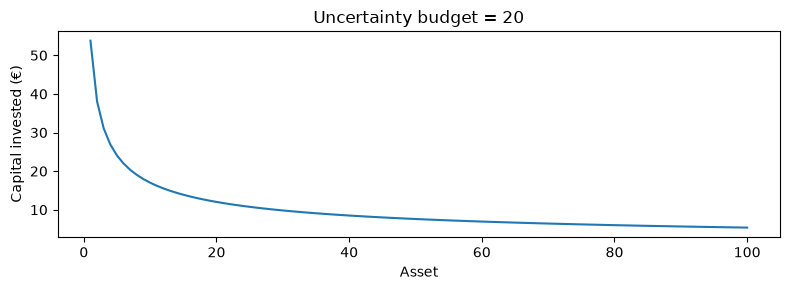

Worst perturbation norms: max = 1, sum = 20
Wealth at this perturbation: €1,129.8958
Wealth minus the counterpart bound: €0.0000


In [12]:
asset_indices = np.arange(1, 101)
nominal_returns = 1.15 + asset_indices * (0.05/100)
return_deviations = (0.05/300) * np.sqrt(45300 * asset_indices)


def build_budget_portfolio(Gamma):
    if not 0 <= Gamma <= 100:
        raise ValueError("Gamma must lie between 0 and 100.")
    model = pyo.ConcreteModel()
    model.indices = pyo.RangeSet(1, 100)
    model.x = pyo.Var(model.indices, domain=pyo.NonNegativeReals)
    model.tau = pyo.Var(domain=pyo.Reals)
    model.mu = pyo.Var(model.indices, domain=pyo.NonNegativeReals)
    model.lam = pyo.Var(domain=pyo.NonNegativeReals)
    model.budget = pyo.Constraint(expr=sum(model.x[i] for i in model.indices) == 1000)
    model.coefficient_bound = pyo.Constraint(
        model.indices, rule=lambda m, i: m.lam + m.mu[i] >= return_deviations[i-1] * m.x[i])
    model.guarantee = pyo.Constraint(
        expr=model.tau + Gamma * model.lam + sum(model.mu[i] for i in model.indices)
        <= sum(nominal_returns[i-1] * model.x[i] for i in model.indices))
    model.wealth = pyo.Objective(expr=model.tau, sense=pyo.maximize)
    return model


def portfolio(Gamma=20, printflag=False):
    model = build_budget_portfolio(Gamma)
    solve_and_load(model, lp_solver)
    allocation = np.array([pyo.value(model.x[i]) for i in model.indices])
    wealth = pyo.value(model.wealth)
    if printflag:
        print(f"Guaranteed terminal wealth: €{wealth:,.4f}\nNet profit: €{wealth-1000:,.4f}")
        print(f"Assets held: {np.count_nonzero(allocation > 1e-6)}")
        ax = pd.Series(allocation, index=asset_indices).plot(figsize=(8, 3))
        ax.set(xlabel="Asset", ylabel="Capital invested (€)", title=f"Uncertainty budget = {Gamma}")
        plt.tight_layout()
        plt.show()
    return wealth, allocation


budget20_wealth, budget20_weights = portfolio(Gamma=20, printflag=True)

largest_coefficients = np.argsort(return_deviations * budget20_weights)[-20:]
budget20_worst_z = np.zeros_like(nominal_returns)
budget20_worst_z[largest_coefficients] = -1
budget20_worst_wealth = (nominal_returns + return_deviations * budget20_worst_z) @ budget20_weights
print(f"Worst perturbation norms: max = {np.max(np.abs(budget20_worst_z)):g}, "
      f"sum = {np.abs(budget20_worst_z).sum():g}")
print(f"Wealth at this perturbation: €{budget20_worst_wealth:,.4f}")
print(f"Wealth minus the counterpart bound: €{format_number(budget20_worst_wealth - budget20_wealth, 4)}")


**(b)** Predict how guaranteed wealth changes as the uncertainty set grows.
Compare the portfolios for integer budgets from 0 to 50, the fractional
budget $12.5$ and the full box at $\Gamma=100$. Plot wealth and the number
of assets held.

The budget bounds $\|z\|_1$, so several partial deviations can share one
unit. At $\Gamma=12.5$, fix each holding at €10 and solve for guaranteed
wealth. Sort the coefficients $s_jx_j$ in decreasing order. Compare the
loss given by the dual with the sum of the 12 largest coefficients plus
half of the 13th.


,Guaranteed wealth (€),Assets held
Uncertainty budget,,
0.0,1200.0000,1
1.0,1182.0230,36
10.0,1148.9780,100
12.5,1144.2075,100
20.0,1129.8958,100
27.0,1116.5383,100
28.0,1115.0270,1
50.0,1115.0270,1
100.0,1115.0270,1


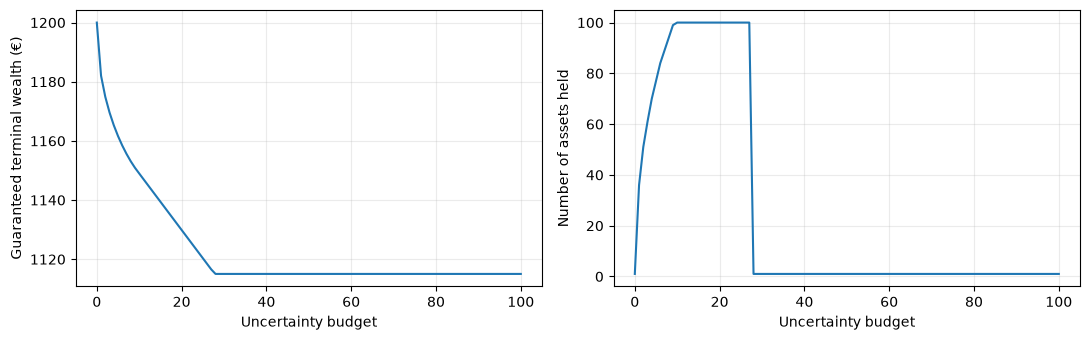

Nominal wealth: €1,175.2500
Worst loss: €43.0374 by sorting and €43.0374 from the dual LP.
Guaranteed wealth: €1,132.2126
Budget multiplier: €3.3277


In [13]:
budgets = sorted([*range(51), 12.5, 100])
budget_solutions = {gamma: portfolio(Gamma=gamma) for gamma in budgets}
budget_sweep = pd.DataFrame({
    "Guaranteed wealth (€)": {g: value for g, (value, allocation) in budget_solutions.items()},
    "Assets held": {g: np.count_nonzero(allocation > 1e-6)
                    for g, (value, allocation) in budget_solutions.items()},
}).rename_axis("Uncertainty budget")
display(budget_sweep.loc[[0, 1, 10, 12.5, 20, 27, 28, 50, 100]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
budget_sweep["Guaranteed wealth (€)"].plot(ax=axes[0], ylabel="Guaranteed terminal wealth (€)")
budget_sweep["Assets held"].plot(ax=axes[1], ylabel="Number of assets held")
for ax in axes:
    ax.set_xlabel("Uncertainty budget")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fixed_portfolio = build_budget_portfolio(12.5)
for holding in fixed_portfolio.x.values():
    holding.fix(10)
solve_and_load(fixed_portfolio, lp_solver)

fixed_nominal_wealth = 10 * nominal_returns.sum()
fixed_sorted_coefficients = np.sort(10 * return_deviations)[::-1]
fixed_loss = fixed_sorted_coefficients[:12].sum() + 0.5 * fixed_sorted_coefficients[12]
fixed_wealth = fixed_nominal_wealth - fixed_loss
dual_wealth = pyo.value(fixed_portfolio.wealth)
assert np.isclose(fixed_wealth, dual_wealth, atol=1e-7, rtol=0)
print(f"Nominal wealth: €{fixed_nominal_wealth:,.4f}")
print(f"Worst loss: €{fixed_loss:,.4f} by sorting and €{fixed_nominal_wealth - dual_wealth:,.4f} from the dual LP.")
print(f"Guaranteed wealth: €{dual_wealth:,.4f}")
print(f"Budget multiplier: €{pyo.value(fixed_portfolio.lam):.4f}")


The sets are nested, from the nominal point at $\Gamma=0$ to the full box
at $\Gamma=100$, so guaranteed wealth cannot increase with the budget.

For integer budgets 10 through 27, all 100 assets are held with equal
coefficients $s_jx_j$, about €1.9082 each. With these holdings, wealth falls
by that amount per unit of budget. At $\Gamma=28$, carrying those holdings
forward would guarantee about €1,114.63, below the €1,115.03 from asset 1.
The latter guarantee holds for every $\Gamma\ge1$ because the budget already permits its full
deviation. At budget 28 the LP switches to asset 1.

With €10 in each asset, the coefficients $s_jx_j$ are distinct. At
$\Gamma=12.5$ the loss is €43.0374 and the budget multiplier is the 13th
largest coefficient, about €3.3277. The fixed portfolio guarantees
€1,132.2126, below the optimal €1,144.2075 at the same budget.


**(c)** This part uses a separate two-dimensional example. Serving demands
$d_1,d_2$ uses $d_1+2d_2$ units of capacity, with a limit of 22. Use the
one-sided budget set with $\Gamma=1$.
$$
d=(4,5)+(2\zeta_1,4\zeta_2),\qquad
0\le\zeta_1,\zeta_2\le1,\qquad \zeta_1+\zeta_2\le\Gamma.
$$

Find the maximum load. A vector in the design set *dominates* an observed
demand if it is at least as large in both coordinates. An observation is
*covered* if such a vector exists. For each of $(3,9)$ and $(6,6)$, decide
whether it is covered and give a dominating vector when one exists. Check
each observed demand against capacity. Would raising the budget to $1.5$
cover $(7,5)$ with the same coordinate bounds?


At $\Gamma=1$, the maximum load is the value of
$$
\begin{aligned}
    \max_{\zeta}\quad &14+2\zeta_1+8\zeta_2\\
    \text{s.t.}\quad &0\le\zeta_1,\zeta_2\le1,\\
    &\zeta_1+\zeta_2\le1.
\end{aligned}
$$
The values at $(0,0)$, $(1,0)$ and $(0,1)$ are $14$, $16$ and $22$,
respectively. The maximum is 22, so the capacity bound holds over
the design set.

- For $(3,9)$, take $\zeta=(0,1)$ to obtain $(4,9)$. The first demand is
  below the baseline, so it uses no budget. The observed load is $21$.
- To dominate $(6,6)$, we need $\zeta_1\ge1$ and $\zeta_2\ge1/4$. Their sum
  exceeds the budget of one. The observed load is $18$, within capacity.
- To dominate $(7,5)$, we need $\zeta_1\ge1.5$. The coordinate bound rules
  this out even at budget $1.5$. The observed load is $17$.


In [14]:
coverage_baseline = np.array([4, 5])
coverage_widths = np.array([2, 4])
load_weights = np.array([1, 2])

vertices = np.array([[0, 0], [1, 0], [0, 1]])
coverage_max_load = ((coverage_baseline + coverage_widths * vertices) @ load_weights).max()
print(f"Maximum load at budget 1: {coverage_max_load:g}")

observed_demands = np.array([[3, 9], [6, 6], [7, 5]])
coverage_budgets = np.array([1, 1, 1.5])
coverage_perturbations = np.maximum(0, (observed_demands - coverage_baseline) / coverage_widths)
is_covered = ((coverage_perturbations <= 1).all(axis=1)
              & (coverage_perturbations.sum(axis=1) <= coverage_budgets))
coverage_witnesses = [
    tuple((coverage_baseline + coverage_widths * zeta).tolist()) if covered else None
    for zeta, covered in zip(coverage_perturbations, is_covered)
]
coverage_loads = observed_demands @ load_weights
witness_labels = [
    f"({witness[0]:g}, {witness[1]:g})" if witness is not None else None
    for witness in coverage_witnesses
]

display(pd.DataFrame({
    "Observed demand": [tuple(d.tolist()) for d in observed_demands],
    "Budget": coverage_budgets,
    "Covered": is_covered,
    "Dominating demand": witness_labels,
    "Observed load": coverage_loads,
}))


Maximum load at budget 1: 22


,Observed demand,Budget,Covered,Dominating demand,Observed load
0,"(3, 9)",1.0,True,"(4, 9)",21
1,"(6, 6)",1.0,False,NaN,18
2,"(7, 5)",1.5,False,NaN,17


## Exercise 4: airline seat allocation with polyhedral uncertainty

As in Lab 4, an airline allocates 200 economy-seat units across first,
business and economy. The three classes use 2, 1.5 and 1 seat units per
seat and earn 3, 2 and 1 revenue units per ticket, respectively. Seat
counts and planned sales are nonnegative integers. Sales cannot exceed
the seats allocated to each class, and the plan must include at least
80 economy-ticket sales.

Let $s=(s_F,s_B,s_E)$ be the sales plan. A ticket in class $i$ has an
uncertain workload score $z_i$, measured relative to the cabin-service
allowance for that class. A negative score means less work than the
allowance. The airline chooses seats and sales before it knows the scores.
Its staffing plan can absorb a total workload score of at most 280, so require
$$
s^\top z\le280\qquad \forall z\in\mathcal Z,
$$
where
$$
\mathcal Z=\left\{z\in\mathbb R^3:
\begin{aligned}
    1&\le z_1+z_2\le2,\\
    1.2&\le z_2+z_3\le1.8,\\
    z_1&\ge-0.9,\qquad z_2\ge-1.1,\qquad z_3\ge0
\end{aligned}
\right\}.
$$

**(a)** Write the inequalities as $Dz\le d$. With $s=(29,41,80)$, solve the
adversarial LP. Check that the maximizing $z$ satisfies both pair-sum
ranges and all three coordinate lower bounds. Give a certificate $y\ge0$ that satisfies
$D^\top y=s$ and $d^\top y=s^\top z$. Report the slack $280-s^\top z$.

**(b)** Use Lecture 10's polyhedral counterpart (slides 19–20) as a guide.
Derive the robust counterpart and solve the resulting mixed-integer linear
model in Pyomo to maximize revenue. Repeat the workload score and certificate
checks for the returned sales plan.


Put the two upper bounds on pair sums first, then the two lower bounds
on those sums, then the three coordinate lower bounds. In the form
$Dz\le d$ this gives
$$
D=\begin{pmatrix}
    1&1&0\\
    0&1&1\\
    -1&-1&0\\
    0&-1&-1\\
    -1&0&0\\
    0&-1&0\\
    0&0&-1
\end{pmatrix},\qquad
d=\begin{pmatrix}2\\1.8\\-1\\-1.2\\0.9\\1.1\\0\end{pmatrix}.
$$

Taking seats equal to sales, the given plan uses 199.5 seat units. For
these fixed sales the adversarial LP and its dual are
$$
\begin{aligned}
    \max_z\quad &s^\top z\\
    \text{s.t.}\quad &Dz\le d,\\
    &z\in\mathbb R^3
\end{aligned}
\qquad
\begin{aligned}
    \min_y\quad &d^\top y\\
    \text{s.t.}\quad &D^\top y=s,\\
    &y\ge0.
\end{aligned}
$$
The set is nonempty since $(0,1,0.5)\in\mathcal Z$. The bounds imply
$-0.9\le z_1\le3.1$, $-1.1\le z_2\le1.8$ and $0\le z_3\le2.9$, so the
adversarial optimum is finite. A feasible pair $z,y$ with matching objectives
certifies the maximum workload score.


In [15]:
airline_D = np.array([[1, 1, 0], [0, 1, 1], [-1, -1, 0], [0, -1, -1],
                      [-1, 0, 0], [0, -1, 0], [0, 0, -1]], dtype=float)
airline_d = np.array([2, 1.8, -1, -1.2, 0.9, 1.1, 0], dtype=float)


def check_airline_score(sales):
    adversary = pyo.ConcreteModel()
    adversary.z = pyo.Var(range(3), domain=pyo.Reals)
    adversary.bounds = pyo.Constraint(
        range(len(airline_d)), rule=lambda m, r:
        sum(airline_D[r, j] * m.z[j] for j in m.z) <= airline_d[r])
    adversary.score = pyo.Objective(
        expr=sum(sales[j] * adversary.z[j] for j in adversary.z), sense=pyo.maximize)
    solve_and_load(adversary, lp_solver)

    dual = pyo.ConcreteModel()
    dual.y = pyo.Var(range(len(airline_d)), domain=pyo.NonNegativeReals)
    dual.balance = pyo.Constraint(
        range(3), rule=lambda m, j:
        sum(airline_D[r, j] * m.y[r] for r in m.y) == sales[j])
    dual.score = pyo.Objective(
        expr=sum(airline_d[r] * dual.y[r] for r in dual.y), sense=pyo.minimize)
    solve_and_load(dual, lp_solver)

    z = np.array([pyo.value(adversary.z[j]) for j in adversary.z])
    y = np.array([pyo.value(dual.y[r]) for r in dual.y])
    z1, z2, z3 = z
    tol = 1e-8
    if not (1 - tol <= z1 + z2 <= 2 + tol and
            1.2 - tol <= z2 + z3 <= 1.8 + tol and
            np.all(z >= np.array([-0.9, -1.1, 0]) - tol)):
        raise ValueError("The maximizing vector z violates the given bounds.")

    score = float(sales @ z)
    dual_score = float(airline_d @ y)
    if not (np.all(y >= -tol) and np.allclose(airline_D.T @ y, sales, atol=tol, rtol=0)
            and np.isclose(score, dual_score, atol=tol, rtol=0)):
        raise ValueError("The dual variables fail to certify the worst-case workload score.")

    slack = 280 - score
    print(f"Worst-case score coefficients z: {z.round(4).tolist()}")
    print(f"Pair sums: {z1 + z2:.4f} and {z2 + z3:.4f}. Both ranges and all lower bounds hold.")
    print(f"Dual certificate y: {y.round(4).tolist()}")
    print(f"Worst-case workload score: {score:.4f}   Dual value: {dual_score:.4f}")
    print(f"Workload score slack: {slack:.4f}")
    return z, y, score, slack


given_sales = np.array([29, 41, 80])
given_worst_case, given_certificate, given_score, given_slack = check_airline_score(given_sales)


Worst-case score coefficients z: [3.1, -1.1, 2.9]
Pair sums: 2.0000 and 1.8000. Both ranges and all lower bounds hold.
Dual certificate y: [29.0, 80.0, 0.0, 0.0, 0.0, 68.0, 0.0]
Worst-case workload score: 276.8000   Dual value: 276.8000
Workload score slack: 3.2000


For the given plan, $z=(3.1,-1.1,2.9)$ has pair sums 2 and 1.8 and satisfies
the coordinate lower bounds. The choice $y=(29,80,0,0,0,68,0)$ is nonnegative,
and
$$
\begin{aligned}
    D^\top y &=(29,29+80-68,80)^\top=s,\\
    d^\top y &=2(29)+1.8(80)+1.1(68)=276.8=s^\top z.
\end{aligned}
$$
The slack is $280-276.8=3.2$. The matching objectives certify the worst-case
workload score. Checking the original bounds also tests the transcription.

By strong duality, the robust inequality holds if and only if there are
multipliers $y\ge0$ with $D^\top y=s$ and $d^\top y\le280$. With seat counts
$n_i$, the full counterpart is
$$
\begin{aligned}
    \max_{n,s,y}\quad &3s_F+2s_B+s_E\\
    \text{s.t.}\quad &2n_F+\tfrac32n_B+n_E\le200,\\
    &s_i\le n_i\qquad (i=F,B,E),\\
    &s_E\ge80,\\
    &D^\top y=s,\qquad d^\top y\le280,\qquad y\ge0,\\
    &n_i,s_i\in\mathbb Z_{\ge0}\qquad (i=F,B,E).
\end{aligned}
$$
The multipliers are continuous. In the outer model they need only certify
a workload score at most 280. Solving the adversarial LP and its dual again
certifies the actual worst case.

The sales plans $(29,41,80)$, $(28,42,81)$ and $(27,44,80)$ all earn the
optimal revenue of 249. Their worst-case workload scores are 276.8, 275.5
and 267.3, respectively. Check whichever plan the solver returns.


In [16]:
robust_airline = pyo.ConcreteModel()
robust_airline.classes = pyo.Set(initialize=["F", "B", "E"], ordered=True)
robust_airline.seats = pyo.Var(robust_airline.classes, domain=pyo.NonNegativeIntegers)
robust_airline.sell = pyo.Var(robust_airline.classes, domain=pyo.NonNegativeIntegers)
robust_airline.capacity = pyo.Constraint(
    expr=2 * robust_airline.seats["F"] + 1.5 * robust_airline.seats["B"] + robust_airline.seats["E"] <= 200)
robust_airline.sales_limit = pyo.Constraint(
    robust_airline.classes, rule=lambda m, c: m.sell[c] <= m.seats[c])
robust_airline.economy_minimum = pyo.Constraint(expr=robust_airline.sell["E"] >= 80)
robust_airline.y = pyo.Var(range(len(airline_d)), domain=pyo.NonNegativeReals)
robust_airline.robust_score = pyo.Constraint(
    expr=sum(airline_d[r] * robust_airline.y[r] for r in range(len(airline_d))) <= 280)
robust_airline.dual_equations = pyo.Constraint(
    range(3), rule=lambda m, j: sum(airline_D[r, j] * m.y[r] for r in range(len(airline_d)))
    == m.sell[["F", "B", "E"][j]])
robust_airline.revenue = pyo.Objective(
    expr=3 * robust_airline.sell["F"] + 2 * robust_airline.sell["B"] + robust_airline.sell["E"],
    sense=pyo.maximize)
solve_and_load(robust_airline, lp_solver)
robust_sales = np.array([pyo.value(robust_airline.sell[c]) for c in robust_airline.classes])
display(pd.DataFrame({
    "Seats": [pyo.value(robust_airline.seats[c]) for c in robust_airline.classes],
    "Planned sales": robust_sales,
}, index=list(robust_airline.classes)).round().astype(int))
print(f"Optimal revenue: {pyo.value(robust_airline.revenue):.0f} revenue units")

worst_case, dual_certificate, worst_score, score_slack = check_airline_score(robust_sales)


,Seats,Planned sales
F,29,29
B,41,41
E,80,80


Optimal revenue: 249 revenue units


Worst-case score coefficients z: [3.1, -1.1, 2.9]
Pair sums: 2.0000 and 1.8000. Both ranges and all lower bounds hold.
Dual certificate y: [29.0, 80.0, 0.0, 0.0, 0.0, 68.0, 0.0]
Worst-case workload score: 276.8000   Dual value: 276.8000
Workload score slack: 3.2000
